# Telecom Customer Churn Prediction & Retention System

**Objective:** identifying potential customers who are likely to churn, recognizing the reasons why they are churning, and ranking them based on their importance.

**Workflow:** This project combines customer analytics and machine learning to understand churn patterns, identify at-risk customers, evaluate predictive performance, and support data-driven retention decisions.

**Dataset:** IBM Telco Customer Churn sample (7,043 customers and 21 original columns).



## 0. Environment setup

In [1]:
%pip -q install xgboost shap

In [2]:
import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment ready.")

Environment ready.


## 1. Business understanding

Customer churn poses a big problem for telecommunication companies since the loss of current customers could lead to a reduction in revenue and an increase in costs incurred when acquiring new customers. Recognizing the customers who are likely to churn helps the telecommunication firms to come up with a strategy for retaining them.

The goal of the project is to study data related to customers, recognize patterns of churn, and use this information to come up with machine learning models that would be used to predict the likelihood of a customer churning.

## 2. Dataset acquisition

In [3]:
DATA_URLS = [
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv",
    "https://raw.githubusercontent.com/plotly/datasets/master/telco-customer-churn-by-IBM.csv"
]
DATA_DIR = "/content/telecom_churn"
os.makedirs(DATA_DIR, exist_ok=True)
DATA_PATH = os.path.join(DATA_DIR, "Telco-Customer-Churn.csv")

df = None
for url in DATA_URLS:
    try:
        candidate = pd.read_csv(url)
        if {"customerID", "Churn"}.issubset(candidate.columns):
            df = candidate.copy()
            df.to_csv(DATA_PATH, index=False)
            print("Loaded dataset from:", url)
            break
    except Exception as exc:
        print("Download attempt failed:", exc)

if df is None:
    raise RuntimeError(
        "Dataset download failed. Upload the CSV in Colab, then run "
        "df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')"
    )

print("Dataset shape:", df.shape)
display(df.head())

Loaded dataset from: https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.65,Yes


In [4]:
print("Rows:", f"{len(df):,}")
print("Columns:", len(df.columns))
print("Column names:", df.columns.tolist())
df.info()

Rows: 7,043
Columns: 21
Column names: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSec

In [5]:
data_dictionary = {
    "customerID": "Unique customer identifier; excluded from model features.",
    "gender": "Customer gender.",
    "SeniorCitizen": "1 if senior citizen, otherwise 0.",
    "Partner": "Whether the customer has a partner.",
    "Dependents": "Whether the customer has dependents.",
    "tenure": "Number of months the customer has stayed.",
    "PhoneService": "Whether phone service is subscribed.",
    "MultipleLines": "Whether multiple phone lines are subscribed.",
    "InternetService": "Internet service type.",
    "OnlineSecurity": "Whether online security is subscribed.",
    "OnlineBackup": "Whether online backup is subscribed.",
    "DeviceProtection": "Whether device protection is subscribed.",
    "TechSupport": "Whether technical support is subscribed.",
    "StreamingTV": "Whether streaming TV is subscribed.",
    "StreamingMovies": "Whether streaming movies are subscribed.",
    "Contract": "Contract duration.",
    "PaperlessBilling": "Whether paperless billing is enabled.",
    "PaymentMethod": "Customer payment method.",
    "MonthlyCharges": "Monthly amount charged.",
    "TotalCharges": "Total amount charged to date; originally stored as text.",
    "Churn": "Whether the customer left within the observed period."
}
display(pd.DataFrame({"Variable": data_dictionary.keys(),
                      "Description": data_dictionary.values()}))

,Variable,Description
0,customerID,Unique customer identifier; excluded from mode...
1,gender,Customer gender.
2,SeniorCitizen,"1 if senior citizen, otherwise 0."
3,Partner,Whether the customer has a partner.
4,Dependents,Whether the customer has dependents.
5,tenure,Number of months the customer has stayed.
6,PhoneService,Whether phone service is subscribed.
7,MultipleLines,Whether multiple phone lines are subscribed.
8,InternetService,Internet service type.
9,OnlineSecurity,Whether online security is subscribed.


## 3. Data quality assessment

In [6]:
raw_df = df.copy()

print("Duplicate rows:", raw_df.duplicated().sum())
print("Duplicate customer IDs:", raw_df["customerID"].duplicated().sum())

missing = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_pct": raw_df.isna().mean() * 100
}).sort_values("missing_pct", ascending=False)
display(missing)

blank_counts = raw_df.select_dtypes(include="object").apply(
    lambda col: col.astype("string").str.strip().eq("").sum()
)
print("Blank/whitespace values:")
display(blank_counts[blank_counts > 0])

print("Target labels:")
display(raw_df["Churn"].value_counts(dropna=False))

Duplicate rows: 0
Duplicate customer IDs: 0


,missing_count,missing_pct
customerID,0,0.000
gender,0,0.000
SeniorCitizen,0,0.000
Partner,0,0.000
Dependents,0,0.000
tenure,0,0.000
PhoneService,0,0.000
MultipleLines,0,0.000
InternetService,0,0.000
OnlineSecurity,0,0.000


Blank/whitespace values:


,0
TotalCharges,11


Target labels:


,count
Churn,
No,5174
Yes,1869


In [7]:
for col in raw_df.select_dtypes(include="object").columns:
    print(f"{col}: {raw_df[col].nunique(dropna=False)} distinct values")

customerID: 7043 distinct values
gender: 2 distinct values
Partner: 2 distinct values
Dependents: 2 distinct values
PhoneService: 2 distinct values
MultipleLines: 3 distinct values
InternetService: 3 distinct values
OnlineSecurity: 3 distinct values
OnlineBackup: 3 distinct values
DeviceProtection: 3 distinct values
TechSupport: 3 distinct values
StreamingTV: 3 distinct values
StreamingMovies: 3 distinct values
Contract: 3 distinct values
PaperlessBilling: 2 distinct values
PaymentMethod: 4 distinct values
TotalCharges: 6531 distinct values
Churn: 2 distinct values


## 4. Data cleaning and validation

`TotalCharges` feature is originally stored as text instead of numeric. Empty data points indicate those customers who have no tenure and hence have incurred no charges yet. They are converted to numeric data type and assigned value zero.

Original data set remains intact, but all data cleaning is done in a different DataFrame. Outliers are not dropped by default since they can be legitimate observations.

In [8]:
data = raw_df.copy()

for col in data.select_dtypes(include="object").columns:
    data[col] = data[col].str.strip()

data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

missing_total = data.loc[
    data["TotalCharges"].isna(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]
print("Missing TotalCharges rows:", len(missing_total))
display(missing_total.head(15))
if len(missing_total):
    display(missing_total["tenure"].value_counts(dropna=False))

data["TotalCharges"] = data["TotalCharges"].fillna(0)
data = data.drop_duplicates().copy()

for col in ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

assert data["customerID"].notna().all()
assert data["customerID"].is_unique
assert data["Churn"].isin(["Yes", "No"]).all()
assert data["tenure"].ge(0).all()
assert data["MonthlyCharges"].ge(0).all()
assert data["TotalCharges"].ge(0).all()

print("Cleaned shape:", data.shape)
print("Remaining missing values:", int(data.isna().sum().sum()))
print("Duplicate IDs:", data["customerID"].duplicated().sum())

Missing TotalCharges rows: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.550,NaN
753,3115-CZMZD,0,20.250,NaN
936,5709-LVOEQ,0,80.850,NaN
1082,4367-NUYAO,0,25.750,NaN
1340,1371-DWPAZ,0,56.050,NaN
3331,7644-OMVMY,0,19.850,NaN
3826,3213-VVOLG,0,25.350,NaN
4380,2520-SGTTA,0,20.000,NaN
5218,2923-ARZLG,0,19.700,NaN
6670,4075-WKNIU,0,73.350,NaN


,count
tenure,
0,11


Cleaned shape: (7043, 21)
Remaining missing values: 0
Duplicate IDs: 0


In [9]:
numeric_original = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
display(data[numeric_original].describe().T)

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,"7,043.000",0.162,0.369,0.000,0.000,0.000,0.000,1.000
tenure,"7,043.000",32.371,24.559,0.000,9.000,29.000,55.000,72.000
MonthlyCharges,"7,043.000",64.762,30.090,18.250,35.500,70.350,89.850,118.750
TotalCharges,"7,043.000","2,279.734","2,266.794",0.000,398.550,"1,394.550","3,786.600","8,684.800"


## 5. Exploratory data analysis

### 5.1 Churn distribution

,customers,percentage
Churn,,
No,5174,73.460
Yes,1869,26.540


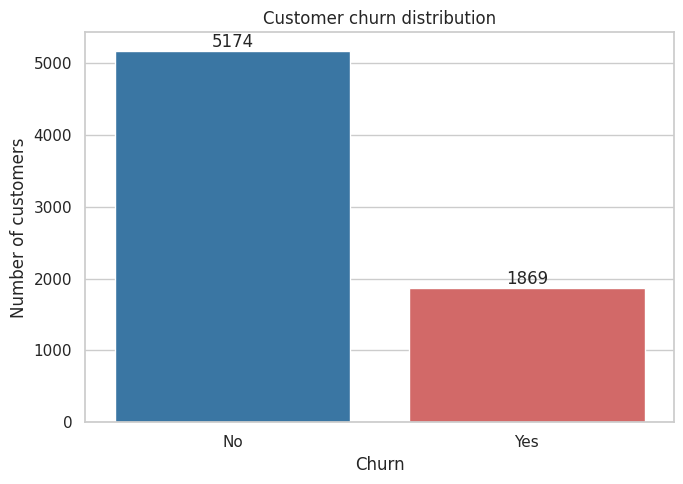

Overall churn rate: 26.5%


In [10]:
churn_counts = data["Churn"].value_counts().reindex(["No", "Yes"])
churn_pct = data["Churn"].value_counts(normalize=True).reindex(["No", "Yes"]) * 100
display(pd.DataFrame({"customers": churn_counts, "percentage": churn_pct.round(2)}))

fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=data, x="Churn", order=["No", "Yes"], hue="Churn",
              palette={"No": "#2878B5", "Yes": "#E45756"}, legend=False, ax=ax)
ax.set(title="Customer churn distribution", xlabel="Churn", ylabel="Number of customers")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.tight_layout()
plt.show()

overall_churn_rate = (data["Churn"] == "Yes").mean()
print(f"Overall churn rate: {overall_churn_rate:.1%}")

### 5.2 Numerical distributions and comparisons

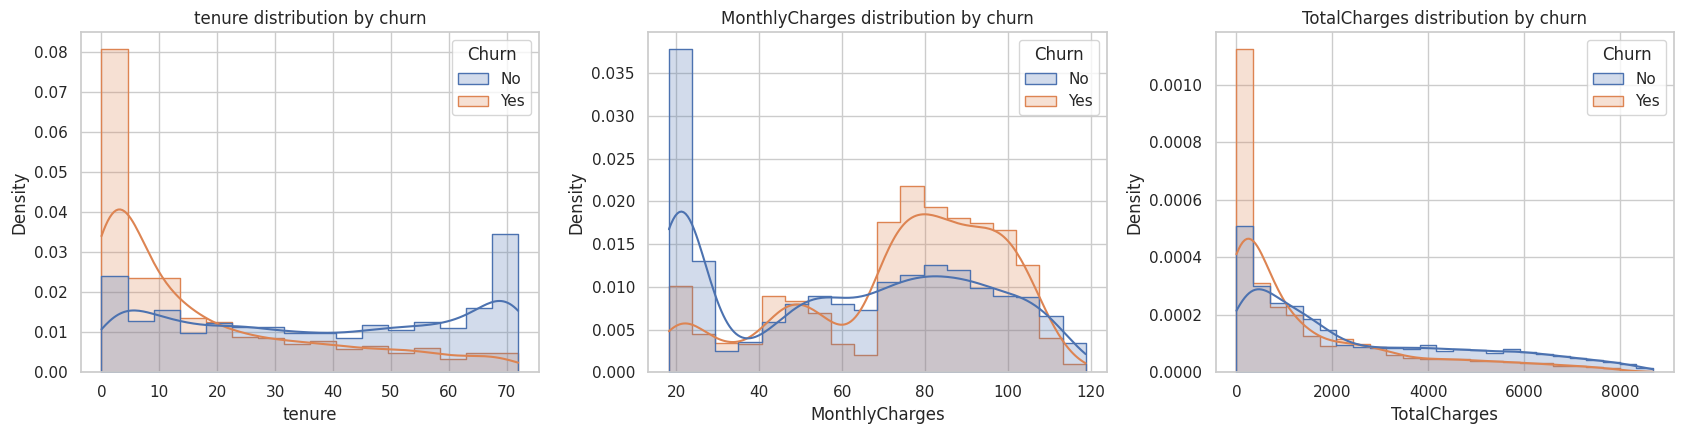

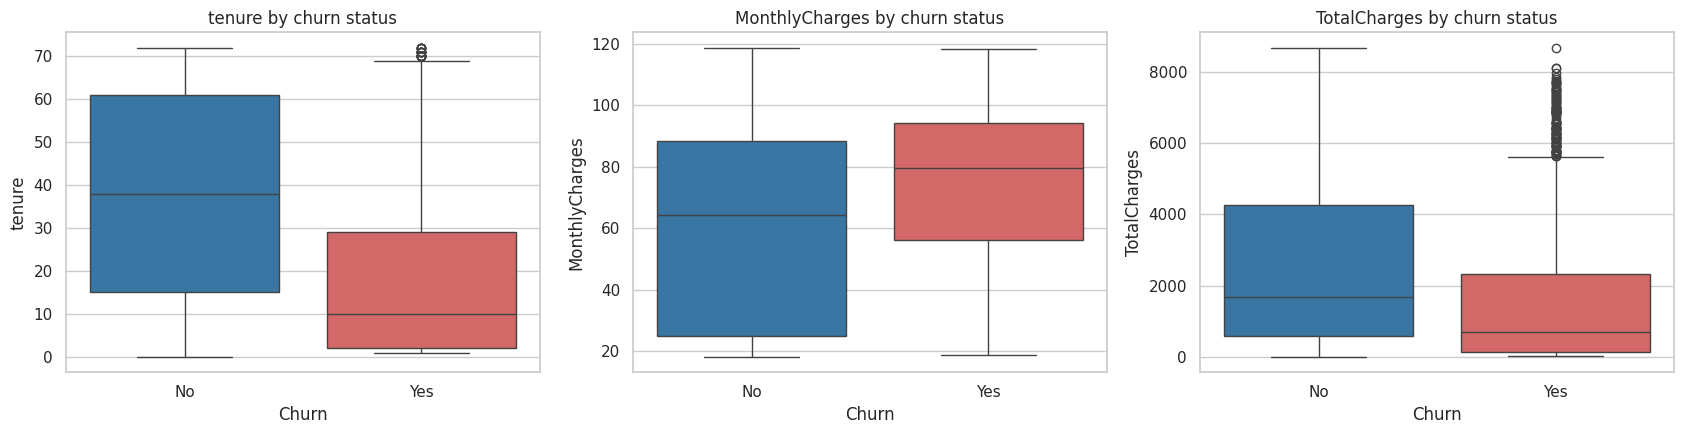

tenure        MonthlyCharges        TotalCharges          
        mean median           mean median         mean    median
Churn                                                           
No    37.570 38.000         61.270 64.430    2,549.910 1,679.520
Yes   17.980 10.000         74.440 79.650    1,531.800   703.550

In [11]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for col, ax in zip(numeric_cols, axes):
    sns.histplot(data=data, x=col, hue="Churn", kde=True,
                 stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(f"{col} distribution by churn")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for col, ax in zip(numeric_cols, axes):
    sns.boxplot(data=data, x="Churn", y=col, hue="Churn",
                order=["No", "Yes"],
                palette={"No": "#2878B5", "Yes": "#E45756"},
                legend=False, ax=ax)
    ax.set_title(f"{col} by churn status")
plt.tight_layout()
plt.show()

display(data.groupby("Churn")[numeric_cols].agg(["mean", "median"]).round(2))

### 5.3 Categorical churn rates

Churn rate by Contract


,Contract,churn_rate_pct
0,Month-to-month,42.700
1,One year,11.300
2,Two year,2.800


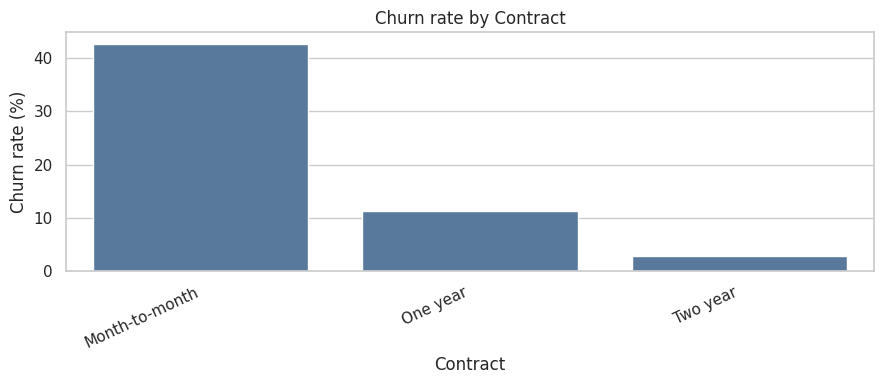

Churn rate by InternetService


,InternetService,churn_rate_pct
0,Fiber optic,41.900
1,DSL,19.000
2,No,7.400


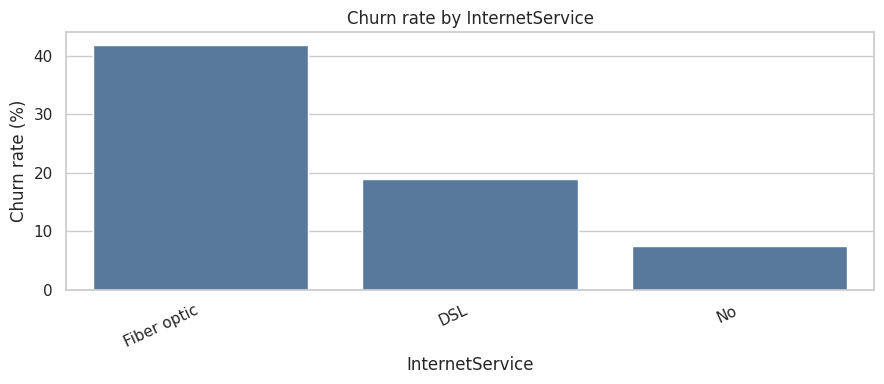

Churn rate by PaymentMethod


,PaymentMethod,churn_rate_pct
0,Electronic check,45.300
1,Mailed check,19.100
2,Bank transfer (automatic),16.700
3,Credit card (automatic),15.200


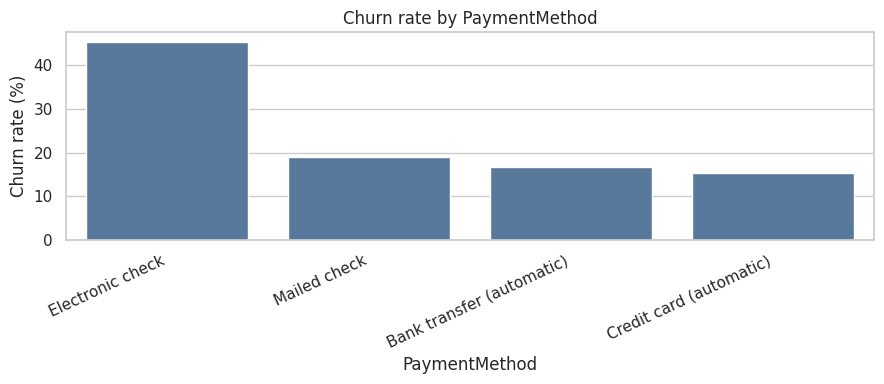

Churn rate by PaperlessBilling


,PaperlessBilling,churn_rate_pct
0,Yes,33.600
1,No,16.300


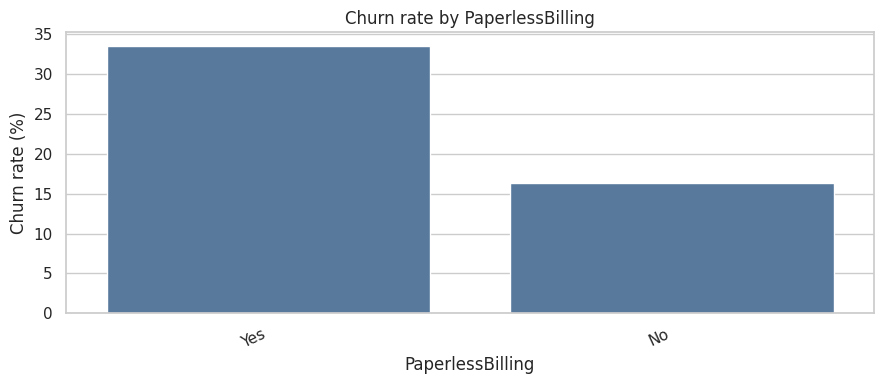

Churn rate by TechSupport


,TechSupport,churn_rate_pct
0,No,41.600
1,Yes,15.200
2,No internet service,7.400


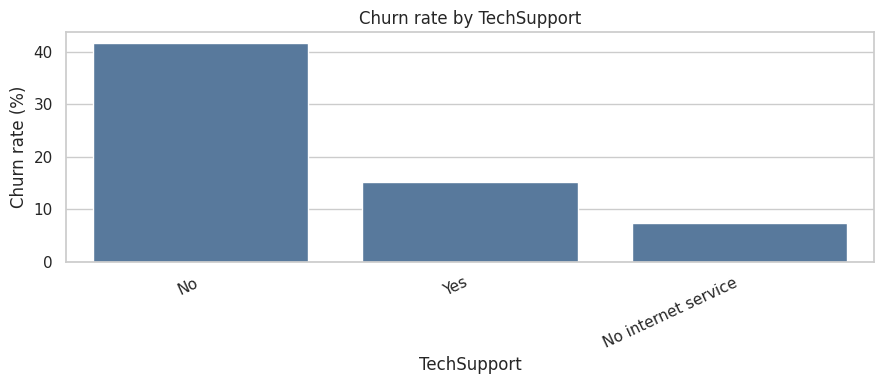

Churn rate by OnlineSecurity


,OnlineSecurity,churn_rate_pct
0,No,41.800
1,Yes,14.600
2,No internet service,7.400


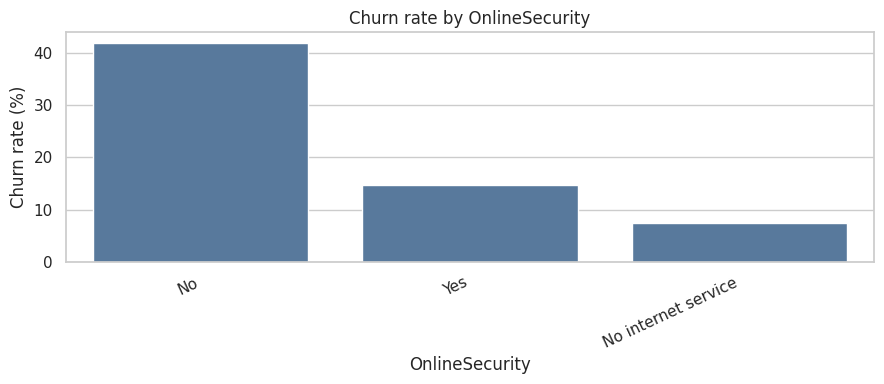

Churn rate by Partner


,Partner,churn_rate_pct
0,No,33.000
1,Yes,19.700


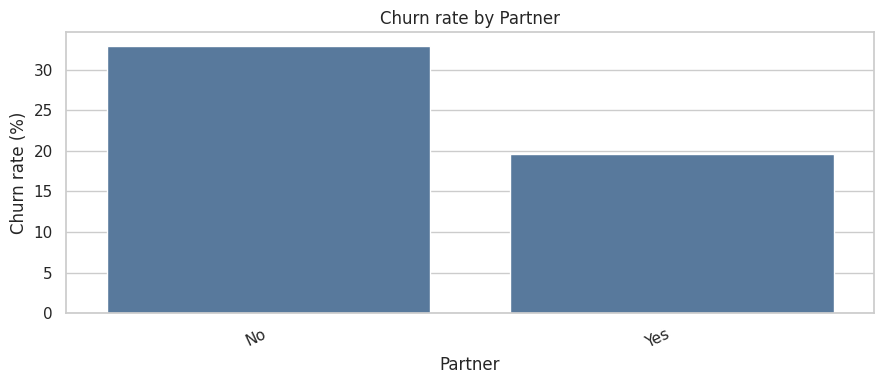

Churn rate by Dependents


,Dependents,churn_rate_pct
0,No,31.300
1,Yes,15.500


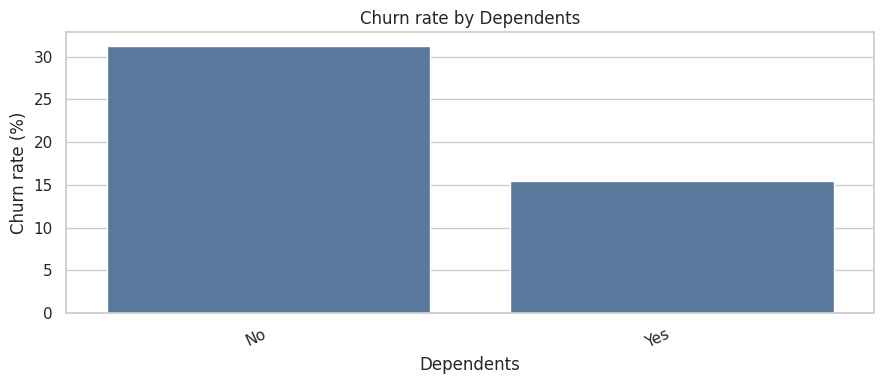

Churn rate by PhoneService


,PhoneService,churn_rate_pct
0,Yes,26.700
1,No,24.900


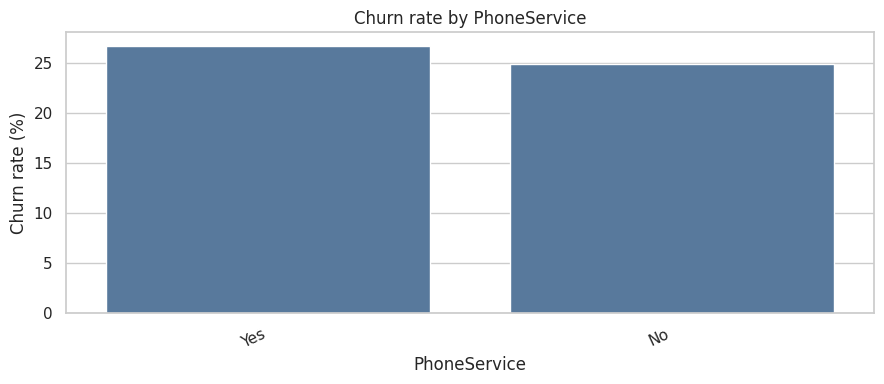

Churn rate by MultipleLines


,MultipleLines,churn_rate_pct
0,Yes,28.600
1,No,25.000
2,No phone service,24.900


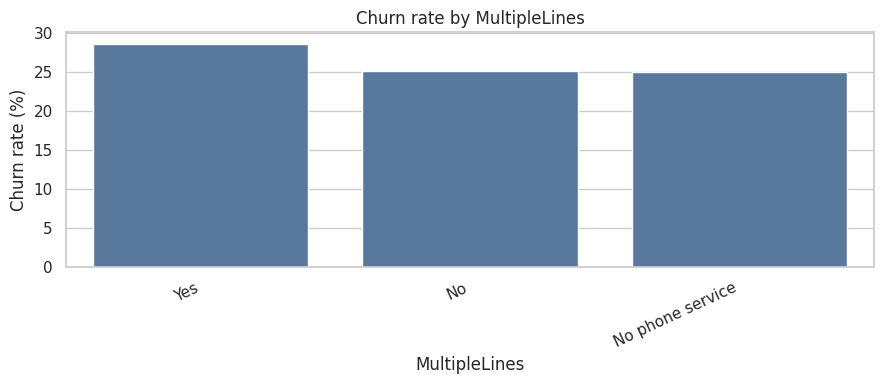

Churn rate by gender


,gender,churn_rate_pct
0,Female,26.900
1,Male,26.200


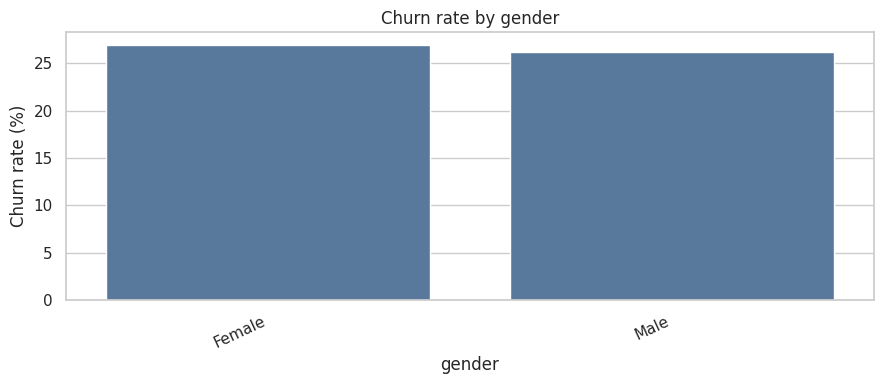

In [12]:
categorical_eda = [
    "Contract", "InternetService", "PaymentMethod", "PaperlessBilling",
    "TechSupport", "OnlineSecurity", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "gender"
]

def churn_rate_by_category(frame, column):
    return (
        frame.groupby(column, dropna=False)["Churn"]
        .apply(lambda s: (s == "Yes").mean() * 100)
        .sort_values(ascending=False)
        .rename("churn_rate_pct")
        .reset_index()
    )

for col in categorical_eda:
    summary = churn_rate_by_category(data, col)
    print(f"Churn rate by {col}")
    display(summary.round(1))
    plt.figure(figsize=(9, 4))
    sns.barplot(data=summary, x=col, y="churn_rate_pct", color="#4C78A8")
    plt.title(f"Churn rate by {col}")
    plt.ylabel("Churn rate (%)")
    plt.xlabel(col)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

### 5.4 Tenure and contract patterns

,tenure_group,churn_rate_pct
0,0-6 months,52.940
1,7-12 months,35.890
2,13-24 months,28.710
3,25-48 months,20.390
4,49-72 months,9.510


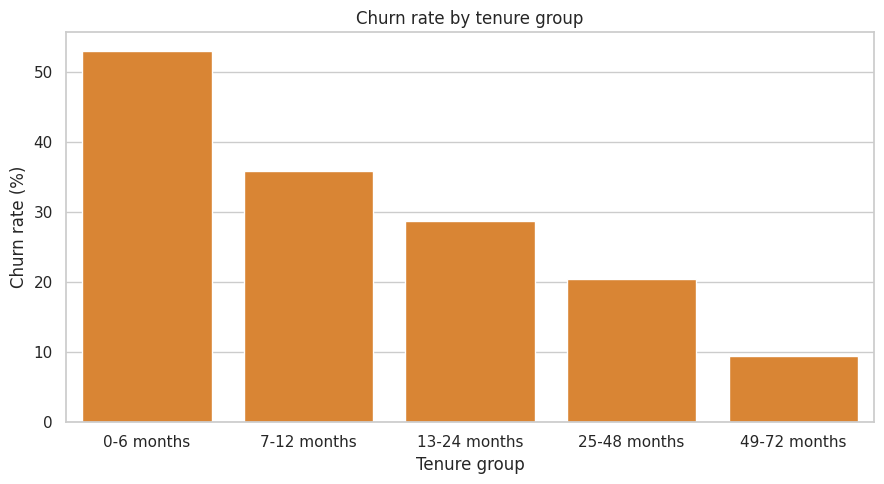

In [13]:
data["tenure_group"] = pd.cut(
    data["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6 months", "7-12 months", "13-24 months", "25-48 months", "49-72 months"]
)
tenure_churn = churn_rate_by_category(data, "tenure_group")
display(tenure_churn.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(data=tenure_churn, x="tenure_group", y="churn_rate_pct", color="#F58518")
plt.title("Churn rate by tenure group")
plt.xlabel("Tenure group")
plt.ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()

### 5.5 Correlation analysis

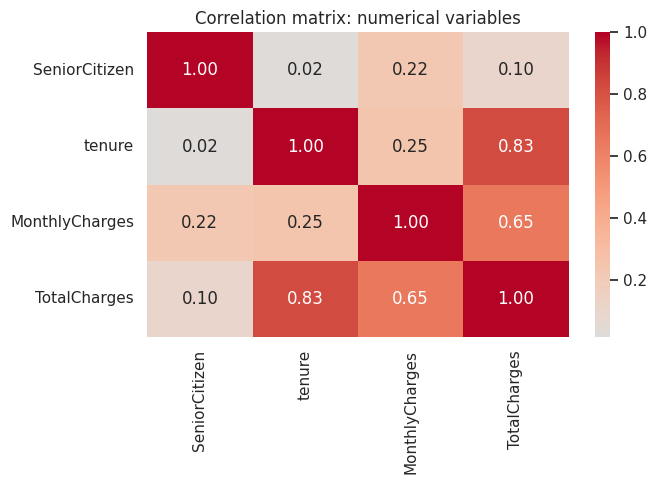

In [14]:
corr = data[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation matrix: numerical variables")
plt.tight_layout()
plt.show()

### EDA interpretation checkpoint
Use the charts and tables above to record the patterns you actually observe. Contract type, tenure, service subscriptions and billing behavior may be associated with churn. These are observational relationships, not causal conclusions. Add a short written interpretation after running the notebook.

## 6. Feature engineering

In [15]:
model_data = data.copy()
model_data["Churn"] = model_data["Churn"].map({"No": 0, "Yes": 1}).astype(int)

service_cols = [
    "PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"
]
model_data["num_services"] = sum(
    model_data[col].eq("Yes").astype(int) for col in service_cols
)

model_data["is_month_to_month"] = model_data["Contract"].eq("Month-to-month").astype(int)
model_data["is_two_year_contract"] = model_data["Contract"].eq("Two year").astype(int)
model_data["is_new_customer"] = model_data["tenure"].le(6).astype(int)
model_data["avg_charge_per_month"] = np.where(
    model_data["tenure"] > 0,
    model_data["TotalCharges"] / model_data["tenure"],
    0
)

display(model_data[[
    "tenure", "num_services", "is_month_to_month",
    "is_new_customer", "avg_charge_per_month", "Churn"
]].head())

,tenure,num_services,is_month_to_month,is_new_customer,avg_charge_per_month,Churn
0,1,1,1,1,29.850,0
1,34,3,0,0,55.574,0
2,2,3,1,1,54.075,1
3,45,3,0,0,40.906,0
4,2,1,1,1,75.825,1


## 7. Customer segmentation (unsupervised learning)

Segments are formed based on customer data through clustering methods where the churn label is not used. The optimum number of segments can be found out by using the measures of inertia and silhouette score.

,k,inertia,silhouette
0,2,"25,754.934",0.370
1,3,"19,353.585",0.358
2,4,"14,719.547",0.410
3,5,"12,142.059",0.381
4,6,"10,150.574",0.400
5,7,"8,830.919",0.389


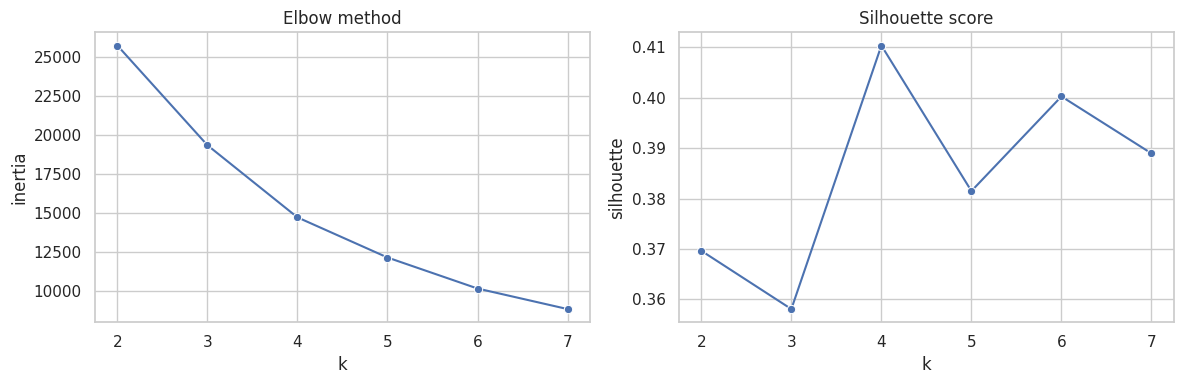

In [16]:
segment_features = [
    "tenure", "MonthlyCharges", "TotalCharges", "num_services",
    "SeniorCitizen", "is_month_to_month"
]
seg_X = model_data[segment_features].copy()
seg_scaler = StandardScaler()
seg_scaled = seg_scaler.fit_transform(seg_X)

k_results = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = km.fit_predict(seg_scaled)
    k_results.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(seg_scaled, labels)
    })

k_results = pd.DataFrame(k_results)
display(k_results)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=k_results, x="k", y="inertia", marker="o", ax=axes[0])
axes[0].set_title("Elbow method")
sns.lineplot(data=k_results, x="k", y="silhouette", marker="o", ax=axes[1])
axes[1].set_title("Silhouette score")
plt.tight_layout()
plt.show()

In [17]:
best_k = int(k_results.loc[k_results["silhouette"].idxmax(), "k"])
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=20)
model_data["customer_segment"] = kmeans.fit_predict(seg_scaled)

segment_profile = model_data.groupby("customer_segment").agg(
    customers=("customerID", "count"),
    avg_tenure=("tenure", "mean"),
    avg_monthly_charges=("MonthlyCharges", "mean"),
    avg_total_charges=("TotalCharges", "mean"),
    avg_services=("num_services", "mean"),
    churn_rate=("Churn", "mean")
).round(3)
segment_profile["churn_rate_pct"] = segment_profile.pop("churn_rate") * 100
display(segment_profile.sort_values("churn_rate_pct", ascending=False))

,customers,avg_tenure,avg_monthly_charges,avg_total_charges,avg_services,churn_rate_pct
customer_segment,,,,,,
3,881,24.792,77.768,"2,012.520",3.322,50.600
1,2789,12.955,59.778,822.184,2.468,40.300
2,1902,58.443,91.616,"5,358.623",5.832,13.000
0,1471,40.012,31.698,"1,222.276",1.892,3.400


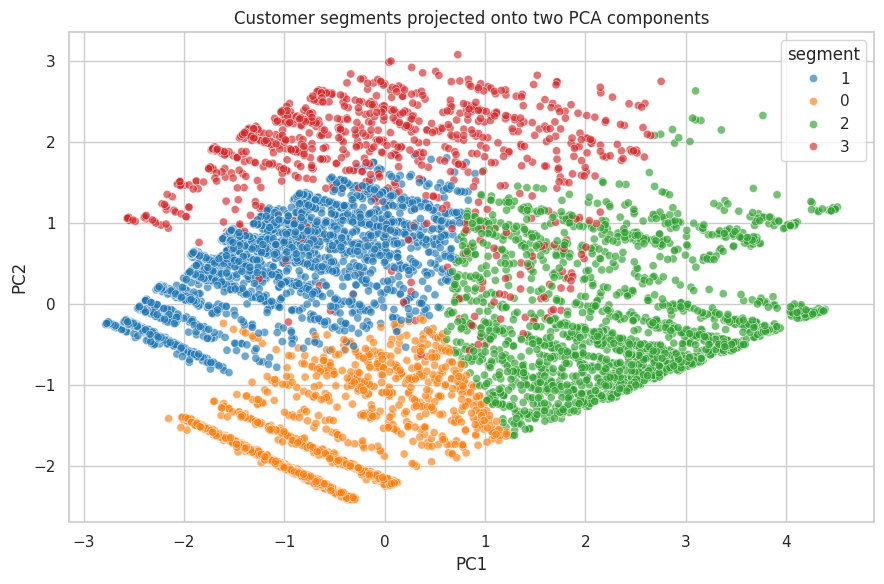

Variance explained by first two components: 0.768


In [18]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
segment_2d = pca.fit_transform(seg_scaled)
plot_segments = pd.DataFrame({
    "PC1": segment_2d[:, 0],
    "PC2": segment_2d[:, 1],
    "segment": model_data["customer_segment"].astype(str).values
})

plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_segments, x="PC1", y="PC2", hue="segment",
                palette="tab10", alpha=0.65, s=35)
plt.title("Customer segments projected onto two PCA components")
plt.tight_layout()
plt.show()
print("Variance explained by first two components:",
      round(pca.explained_variance_ratio_.sum(), 3))

## 8. Train, validation and test split

We hold out 20% for final testing. The remaining 80% is split into training and validation sets, giving approximately 60% training, 20% validation and 20% test. Stratification preserves the target proportion. The customer ID, target and cluster label are excluded from model features.

In [19]:
excluded = ["customerID", "Churn", "customer_segment", "tenure_group"]
feature_cols = [c for c in model_data.columns if c not in excluded]
X = model_data[feature_cols].copy()
y = model_data["Churn"].copy()

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_trainval, y_trainval, test_size=0.25,
    stratify=y_trainval, random_state=RANDOM_STATE
)

for name, target in [("Train", y_train), ("Validation", y_valid), ("Test", y_test)]:
    print(f"{name}: {len(target):,} rows | churn rate: {target.mean():.3f}")

Train: 4,225 rows | churn rate: 0.265
Validation: 1,409 rows | churn rate: 0.265
Test: 1,409 rows | churn rate: 0.265


In [20]:
numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number", "bool"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numeric features: 9
Categorical features: 15


## 9. Train and compare classification models

We will evaluate a baseline using a majority class dummy, along with Logistic Regression, Decision Tree, Random Forest, Extra Trees, and XGBoost. Each preprocessing pipeline will be fit independently in each model pipeline. Where appropriate, class weighting will be applied. We will maintain natural class distributions for validation and testing sets.

In [21]:
models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=20,
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=3, max_features="sqrt",
        class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=400, min_samples_leaf=3, max_features="sqrt",
        class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE
    )
}

try:
    from xgboost import XGBClassifier
    pos_weight = (y_train == 0).sum() / max((y_train == 1).sum(), 1)
    models["XGBoost"] = XGBClassifier(
        n_estimators=400, max_depth=3, learning_rate=0.04,
        subsample=0.85, colsample_bytree=0.85, reg_lambda=1.0,
        objective="binary:logistic", eval_metric="logloss",
        scale_pos_weight=pos_weight, random_state=RANDOM_STATE, n_jobs=-1
    )
except Exception as exc:
    print("XGBoost unavailable; other models will be used:", exc)

pipelines = {
    name: Pipeline([("preprocess", preprocessor), ("model", estimator)])
    for name, estimator in models.items()
}

In [22]:
def positive_probability(fitted_pipeline, features):
    # Return the probability corresponding to class label 1 (churn).
    classes = list(fitted_pipeline.named_steps["model"].classes_)
    positive_index = classes.index(1)
    return fitted_pipeline.predict_proba(features)[:, positive_index]

validation_rows = []
fitted_models = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    valid_prob = positive_probability(pipe, X_valid)
    valid_pred = (valid_prob >= 0.50).astype(int)

    validation_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_valid, valid_pred),
        "precision": precision_score(y_valid, valid_pred, zero_division=0),
        "recall": recall_score(y_valid, valid_pred, zero_division=0),
        "f1": f1_score(y_valid, valid_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_valid, valid_prob),
        "pr_auc": average_precision_score(y_valid, valid_prob)
    })

validation_results = pd.DataFrame(validation_rows).sort_values(
    "pr_auc", ascending=False
).reset_index(drop=True)
display(validation_results.round(4))

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.745,0.513,0.778,0.619,0.839,0.652
1,XGBoost,0.740,0.506,0.765,0.609,0.836,0.642
2,Random Forest,0.780,0.574,0.666,0.616,0.833,0.635
3,Extra Trees,0.760,0.536,0.717,0.613,0.823,0.606
4,Decision Tree,0.729,0.493,0.799,0.610,0.824,0.597
5,Dummy baseline,0.735,0.000,0.000,0.000,0.500,0.265


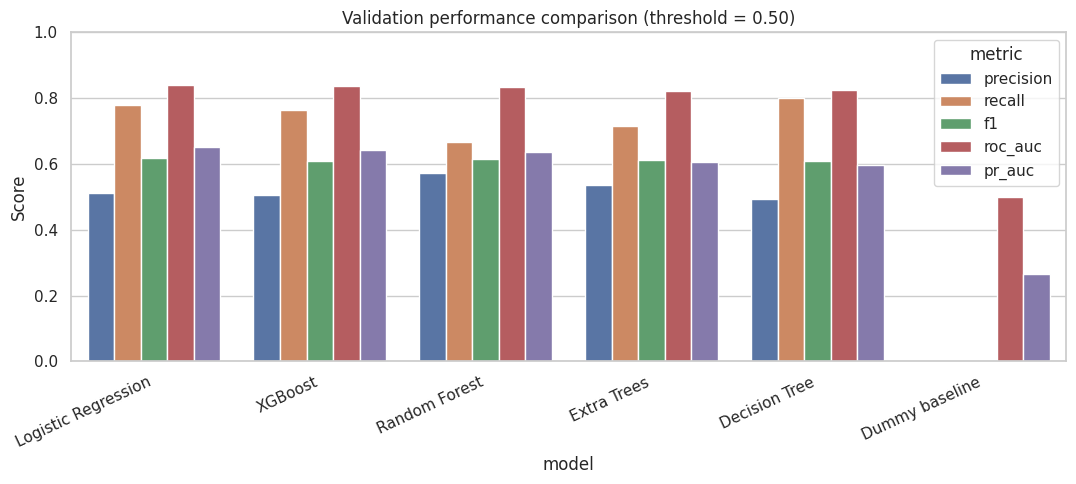

In [23]:
plot_df = validation_results.melt(
    id_vars="model",
    value_vars=["precision", "recall", "f1", "roc_auc", "pr_auc"],
    var_name="metric", value_name="score"
)
plt.figure(figsize=(11, 5))
sns.barplot(data=plot_df, x="model", y="score", hue="metric")
plt.title("Validation performance comparison (threshold = 0.50)")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 10. Select the model and decision threshold

Selection of the best model will be based on validation PR-AUC while adjusting the probability threshold for maximum validation F1. The final threshold will also depend on the capacity of the retention team and cost of errors.

In [24]:
best_model_name = validation_results.iloc[0]["model"]
best_pipeline = fitted_models[best_model_name]
valid_prob = positive_probability(best_pipeline, X_valid)

threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.05):
    pred = (valid_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_valid, pred, zero_division=0),
        "recall": recall_score(y_valid, pred, zero_division=0),
        "f1": f1_score(y_valid, pred, zero_division=0),
        "customers_flagged_pct": pred.mean() * 100
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(3))

,threshold,precision,recall,f1,customers_flagged_pct
0,0.100,0.342,0.976,0.507,75.656
1,0.150,0.367,0.968,0.532,69.979
2,0.200,0.390,0.944,0.552,64.301
3,0.250,0.401,0.917,0.558,60.681
4,0.300,0.422,0.906,0.576,57.062
5,0.350,0.436,0.880,0.583,53.513
6,0.400,0.457,0.853,0.595,49.539
7,0.450,0.493,0.810,0.613,43.648
8,0.500,0.513,0.778,0.618,40.241
9,0.550,0.546,0.741,0.629,35.983


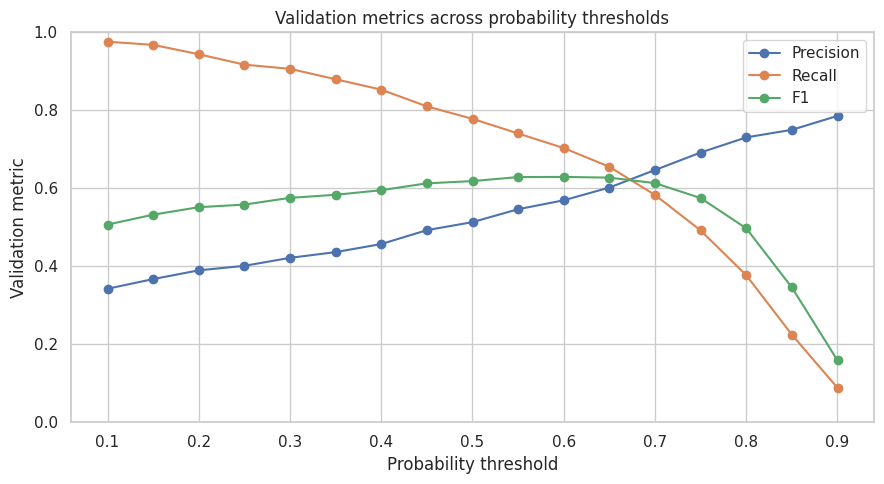

Selected model: Logistic Regression
Selected validation threshold: 0.6


In [25]:
fig, ax = plt.subplots(figsize=(9, 5))
for metric in ["precision", "recall", "f1"]:
    ax.plot(threshold_results["threshold"], threshold_results[metric],
            marker="o", label=metric.title())
ax.set_xlabel("Probability threshold")
ax.set_ylabel("Validation metric")
ax.set_ylim(0, 1)
ax.set_title("Validation metrics across probability thresholds")
ax.legend()
plt.tight_layout()
plt.show()

best_threshold = float(
    threshold_results.loc[threshold_results["f1"].idxmax(), "threshold"]
)
print("Selected model:", best_model_name)
print("Selected validation threshold:", round(best_threshold, 2))

## 11. Final evaluation on the untouched test set

In [26]:
test_prob = positive_probability(best_pipeline, X_test)
test_pred = (test_prob >= best_threshold).astype(int)

final_metrics = {
    "model": best_model_name,
    "threshold": best_threshold,
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred, zero_division=0),
    "recall": recall_score(y_test, test_pred, zero_division=0),
    "f1": f1_score(y_test, test_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, test_prob),
    "pr_auc": average_precision_score(y_test, test_prob)
}
display(pd.DataFrame([final_metrics]).round(4))
print(classification_report(
    y_test, test_pred, target_names=["Retained", "Churned"]
))

,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.600,0.774,0.559,0.711,0.626,0.846,0.656


              precision    recall  f1-score   support

    Retained       0.88      0.80      0.84      1035
     Churned       0.56      0.71      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409



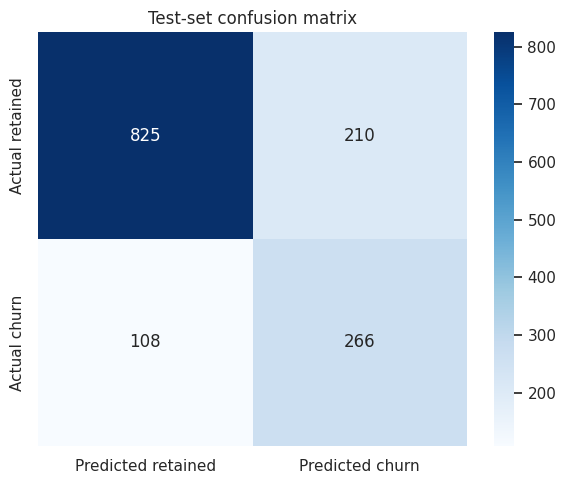

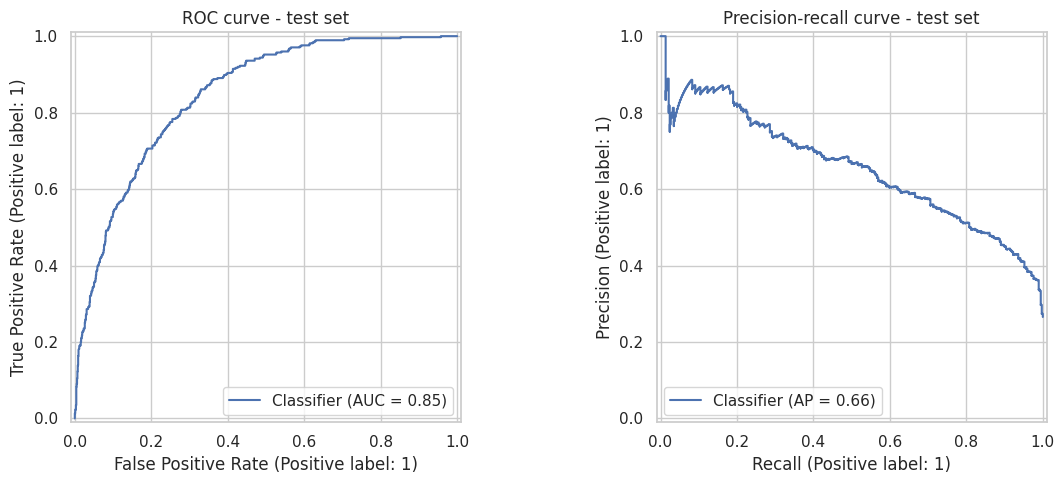

In [27]:
cm = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted retained", "Predicted churn"],
            yticklabels=["Actual retained", "Actual churn"])
plt.title("Test-set confusion matrix")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, test_prob, ax=axes[0])
axes[0].set_title("ROC curve - test set")
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=axes[1])
axes[1].set_title("Precision-recall curve - test set")
plt.tight_layout()
plt.show()

## 12. Model interpretation with permutation importance

Permutation importance measures how much validation performance falls when a feature is shuffled. It can be applied to the complete pipeline and provides an interpretable, model-agnostic diagnostic. Importance indicates predictive association, not causation.

,feature,importance_mean,importance_std
4,tenure,0.108,0.007
7,InternetService,0.081,0.011
23,avg_charge_per_month,0.054,0.010
17,MonthlyCharges,0.041,0.009
22,is_new_customer,0.039,0.006
20,is_month_to_month,0.023,0.006
21,is_two_year_contract,0.015,0.006
11,TechSupport,0.012,0.004
8,OnlineSecurity,0.011,0.007
13,StreamingMovies,0.011,0.004


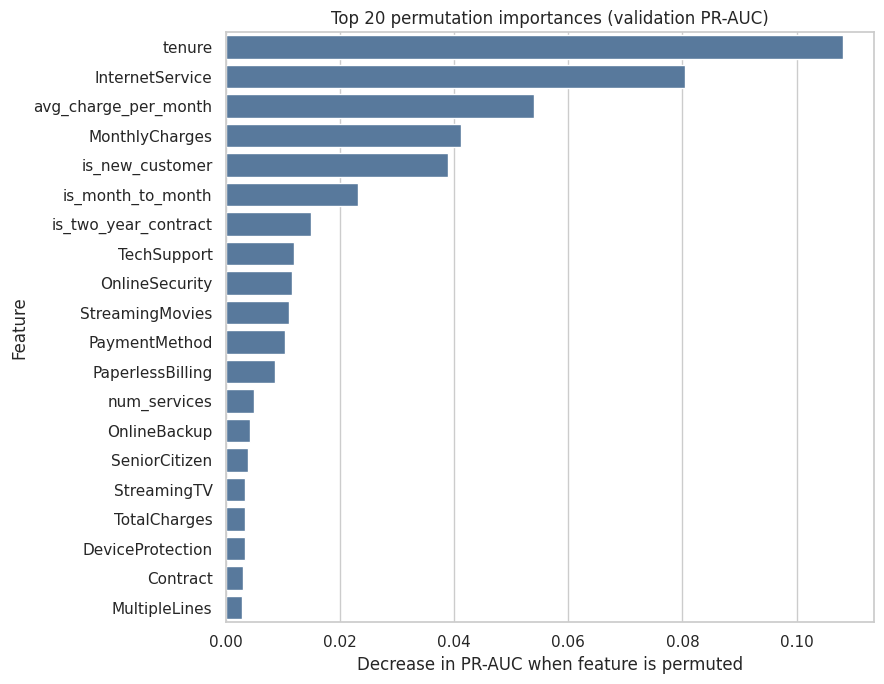

In [28]:
perm = permutation_importance(
    best_pipeline, X_valid, y_valid,
    scoring="average_precision", n_repeats=8,
    random_state=RANDOM_STATE, n_jobs=-1
)
importance_df = pd.DataFrame({
    "feature": X_valid.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_df.head(20).round(4))

plt.figure(figsize=(9, 7))
sns.barplot(data=importance_df.head(20), y="feature",
            x="importance_mean", color="#4C78A8")
plt.title("Top 20 permutation importances (validation PR-AUC)")
plt.xlabel("Decrease in PR-AUC when feature is permuted")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [29]:
# SHAP summary for tree-based models. Skip safely if unsupported.
try:
    import shap
    estimator = best_pipeline.named_steps["model"]
    fitted_preprocessor = best_pipeline.named_steps["preprocess"]
    sample_X = X_valid.sample(min(300, len(X_valid)), random_state=RANDOM_STATE)
    transformed = fitted_preprocessor.transform(sample_X)
    if hasattr(transformed, "toarray"):
        transformed = transformed.toarray()
    names = fitted_preprocessor.get_feature_names_out()

    if best_model_name in ["Random Forest", "Extra Trees", "XGBoost"]:
        explainer = shap.TreeExplainer(estimator)
        shap_values = explainer.shap_values(transformed)
        if isinstance(shap_values, list):
            shap_values = shap_values[1]
        if getattr(shap_values, "ndim", 0) == 3:
            shap_values = shap_values[:, :, 1]
        shap.summary_plot(
            shap_values, transformed, feature_names=names,
            max_display=20, show=True
        )
    else:
        print("SHAP TreeExplainer skipped for the selected non-tree model.")
except Exception as exc:
    print("Optional SHAP analysis could not be completed:", exc)

SHAP TreeExplainer skipped for the selected non-tree model.


## 13. Customer risk scoring and retention prioritization

We score the held-out test customers to demonstrate ranking on unseen records. Customer IDs are included only in the output for record identification; they were not used as model inputs. Risk bands are operational categories, not guarantees of churn.

In [30]:
scored_customers = X_test.copy()
scored_customers.insert(0, "customerID", data.loc[X_test.index, "customerID"])
scored_customers["actual_churn"] = y_test
scored_customers["churn_probability"] = test_prob
scored_customers["predicted_churn"] = test_pred
scored_customers["risk_band"] = pd.cut(
    scored_customers["churn_probability"],
    bins=[-0.001, 0.30, 0.60, 1.001],
    labels=["Low", "Medium", "High"]
)

risk_summary = scored_customers.groupby("risk_band", observed=False).agg(
    customers=("customerID", "count"),
    avg_churn_probability=("churn_probability", "mean"),
    actual_churn_rate=("actual_churn", "mean"),
    avg_monthly_charges=("MonthlyCharges", "mean")
).round(3)
display(risk_summary)

,customers,avg_churn_probability,actual_churn_rate,avg_monthly_charges
risk_band,,,,
Low,624,0.109,0.048,53.959
Medium,309,0.456,0.252,63.534
High,476,0.777,0.559,77.729


In [31]:
outreach_columns = [
    "customerID", "churn_probability", "risk_band",
    "Contract", "tenure", "MonthlyCharges", "InternetService",
    "PaymentMethod", "TechSupport", "OnlineSecurity"
]
outreach_list = (
    scored_customers.sort_values("churn_probability", ascending=False)
    [outreach_columns].reset_index(drop=True)
)
display(outreach_list.head(25))

OUTREACH_PATH = os.path.join(DATA_DIR, "customer_retention_priority_list.csv")
outreach_list.to_csv(OUTREACH_PATH, index=False)
print("Saved:", OUTREACH_PATH)

,customerID,churn_probability,risk_band,Contract,tenure,MonthlyCharges,InternetService,PaymentMethod,TechSupport,OnlineSecurity
0,5178-LMXOP,0.959,High,Month-to-month,1,95.100,Fiber optic,Electronic check,No,No
1,6023-YEBUP,0.955,High,Month-to-month,3,100.950,Fiber optic,Electronic check,No,No
2,1400-MMYXY,0.954,High,Month-to-month,3,105.900,Fiber optic,Electronic check,No,No
3,9057-SIHCH,0.952,High,Month-to-month,3,96.600,Fiber optic,Electronic check,No,No
4,0295-PPHDO,0.952,High,Month-to-month,1,95.450,Fiber optic,Electronic check,No,No
5,2545-EBUPK,0.952,High,Month-to-month,2,84.050,Fiber optic,Electronic check,No,No
6,4750-ZRXIU,0.947,High,Month-to-month,4,84.600,Fiber optic,Electronic check,No,No
7,1069-XAIEM,0.946,High,Month-to-month,1,85.050,Fiber optic,Electronic check,No,No
8,2865-TCHJW,0.944,High,Month-to-month,4,89.200,Fiber optic,Electronic check,No,No
9,6630-UJZMY,0.942,High,Month-to-month,4,83.250,Fiber optic,Electronic check,No,No


Saved: /content/telecom_churn/customer_retention_priority_list.csv


In [32]:
high_risk = scored_customers[scored_customers["risk_band"] == "High"]
revenue_exposure_proxy = high_risk["MonthlyCharges"].sum()

print("High-risk customers in scored sample:", len(high_risk))
print(f"Sum of monthly charges for high-risk customers: ${revenue_exposure_proxy:,.2f}")
print(
    "Caution: this is an exposure proxy, not expected lost revenue. "
    "It assumes all high-risk customers churn and ignores margins, timing and intervention effects."
)

High-risk customers in scored sample: 476
Sum of monthly charges for high-risk customers: $36,999.15
Caution: this is an exposure proxy, not expected lost revenue. It assumes all high-risk customers churn and ignores margins, timing and intervention effects.


## 14. Recommendations and limitations

**Retention Recommendations**

From the analysis, the possible ways of retention are to provide long-term contracts, offer better onboarding services, technical assistance, and also consider the plans of those clients who have very high monthly charges. These measures should be tested in order to determine their actual effect on the customer retention.

**Limitations**

1. The dataset is a sample taken from a fictional telecom company.
2. Data does not provide for time-based analysis.
3. Correlations do not mean causality.
4. The model needs to be validated using company data.
5. Campaigns need to be tested to measure their effectiveness.

In [33]:
print("Churn rate by contract (%):")
contract_churn = (
    data.groupby("Contract")["Churn"]
    .apply(lambda s: (s == "Yes").mean() * 100)
    .sort_values(ascending=False)
)
display(contract_churn.round(1))

print(f"Overall churn rate: {data['Churn'].eq('Yes').mean():.1%}")
print("Selected validation model:", best_model_name)
print(f"Test PR-AUC: {final_metrics['pr_auc']:.3f}")
print(f"Test ROC-AUC: {final_metrics['roc_auc']:.3f}")

Churn rate by contract (%):


,Churn
Contract,
Month-to-month,42.700
One year,11.300
Two year,2.800


Overall churn rate: 26.5%
Selected validation model: Logistic Regression
Test PR-AUC: 0.656
Test ROC-AUC: 0.846


## 15. Save model and project outputs

In [34]:
MODEL_PATH = os.path.join(DATA_DIR, "telecom_churn_pipeline.joblib")
METADATA_PATH = os.path.join(DATA_DIR, "model_metadata.json")
METRICS_PATH = os.path.join(DATA_DIR, "test_metrics.json")
IMPORTANCE_PATH = os.path.join(DATA_DIR, "permutation_importance.csv")

joblib.dump(best_pipeline, MODEL_PATH)
importance_df.to_csv(IMPORTANCE_PATH, index=False)

metadata = {
    "model_name": best_model_name,
    "decision_threshold": float(best_threshold),
    "target": "Churn (1 = Yes, 0 = No)",
    "feature_columns": feature_cols,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "random_state": RANDOM_STATE,
    "dataset": "IBM Telco Customer Churn sample"
}
with open(METADATA_PATH, "w") as f:
    json.dump(metadata, f, indent=2)

with open(METRICS_PATH, "w") as f:
    json.dump({
        k: (float(v) if isinstance(v, (np.floating, np.integer)) else v)
        for k, v in final_metrics.items()
    }, f, indent=2)

print("Saved model:", MODEL_PATH)
print("Saved metadata:", METADATA_PATH)
print("Saved metrics:", METRICS_PATH)
print("Saved feature importance:", IMPORTANCE_PATH)

Saved model: /content/telecom_churn/telecom_churn_pipeline.joblib
Saved metadata: /content/telecom_churn/model_metadata.json
Saved metrics: /content/telecom_churn/test_metrics.json
Saved feature importance: /content/telecom_churn/permutation_importance.csv


In [35]:
# Verify that the saved model reloads and predicts successfully.
loaded_pipeline = joblib.load(MODEL_PATH)
reloaded_probabilities = positive_probability(loaded_pipeline, X_test.iloc[:10])
print("First 10 probabilities from reloaded model:")
print(np.round(reloaded_probabilities, 4))

First 10 probabilities from reloaded model:
[0.1045 0.8657 0.1642 0.5878 0.0613 0.7882 0.6561 0.2438 0.011  0.5428]


In [36]:

from google.colab import files

files.download(MODEL_PATH)
files.download(METADATA_PATH)
files.download(METRICS_PATH)
files.download(OUTREACH_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 16. Summary

In [37]:
project_summary = {
    "cleaned_customer_records": int(len(data)),
    "original_variables": int(raw_df.shape[1]),
    "overall_churn_rate": round(float(data["Churn"].eq("Yes").mean()), 4),
    "customer_segments": int(best_k),
    "selected_model": best_model_name,
    "selected_threshold": round(float(best_threshold), 3),
    "test_precision": round(float(final_metrics["precision"]), 4),
    "test_recall": round(float(final_metrics["recall"]), 4),
    "test_f1": round(float(final_metrics["f1"]), 4),
    "test_roc_auc": round(float(final_metrics["roc_auc"]), 4),
    "test_pr_auc": round(float(final_metrics["pr_auc"]), 4)
}
display(pd.Series(project_summary, name="Project results"))

,Project results
cleaned_customer_records,7043
original_variables,21
overall_churn_rate,0.265
customer_segments,4
selected_model,Logistic Regression
selected_threshold,0.600
test_precision,0.559
test_recall,0.711
test_f1,0.626
test_roc_auc,0.846
